In [4]:
from sklearn.manifold import TSNE
import numpy as np
import matplotlib.pyplot as plt
import umap

In [5]:
E_pos = np.load("proj/sae_E.npy")
E_neg = np.load("proj/neg_sae_E.npy")

In [7]:
E_pos.shape, E_neg.shape

((130802, 16), (130802, 16))

In [8]:
X_pos = np.load("proj/X_pos.npy")
X_neg = np.load("proj/X_neg.npy")

In [9]:
open_rate = X_pos.mean(axis=0)
non_open_rate = X_neg.mean(axis=0)

In [4]:
tsne_pos = TSNE(n_components=2, random_state=42, n_jobs=2)
tsne_neg = TSNE(n_components=2, random_state=42, n_jobs=2)

In [5]:
E_pos_tsne = tsne_pos.fit_transform(E_pos)
E_neg_tsne = tsne_neg.fit_transform(E_neg)

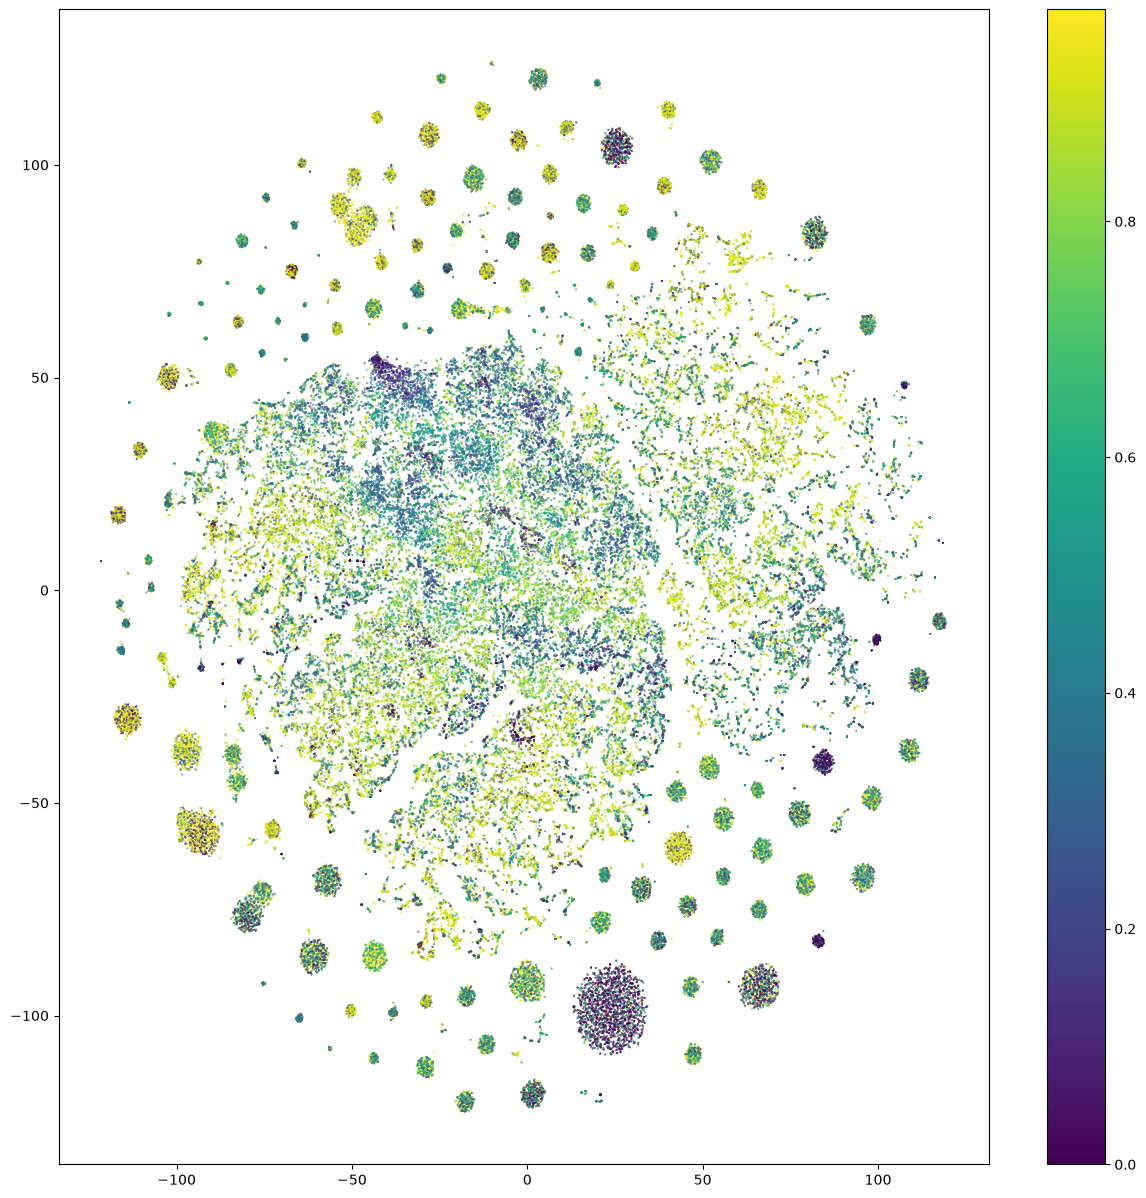

In [25]:
plt.figure(figsize=(15,15))

plt.scatter(E_neg_tsne[:, 0], E_neg_tsne[:, 1],c=non_open_rate, s=0.1)
plt.colorbar()
plt.show()

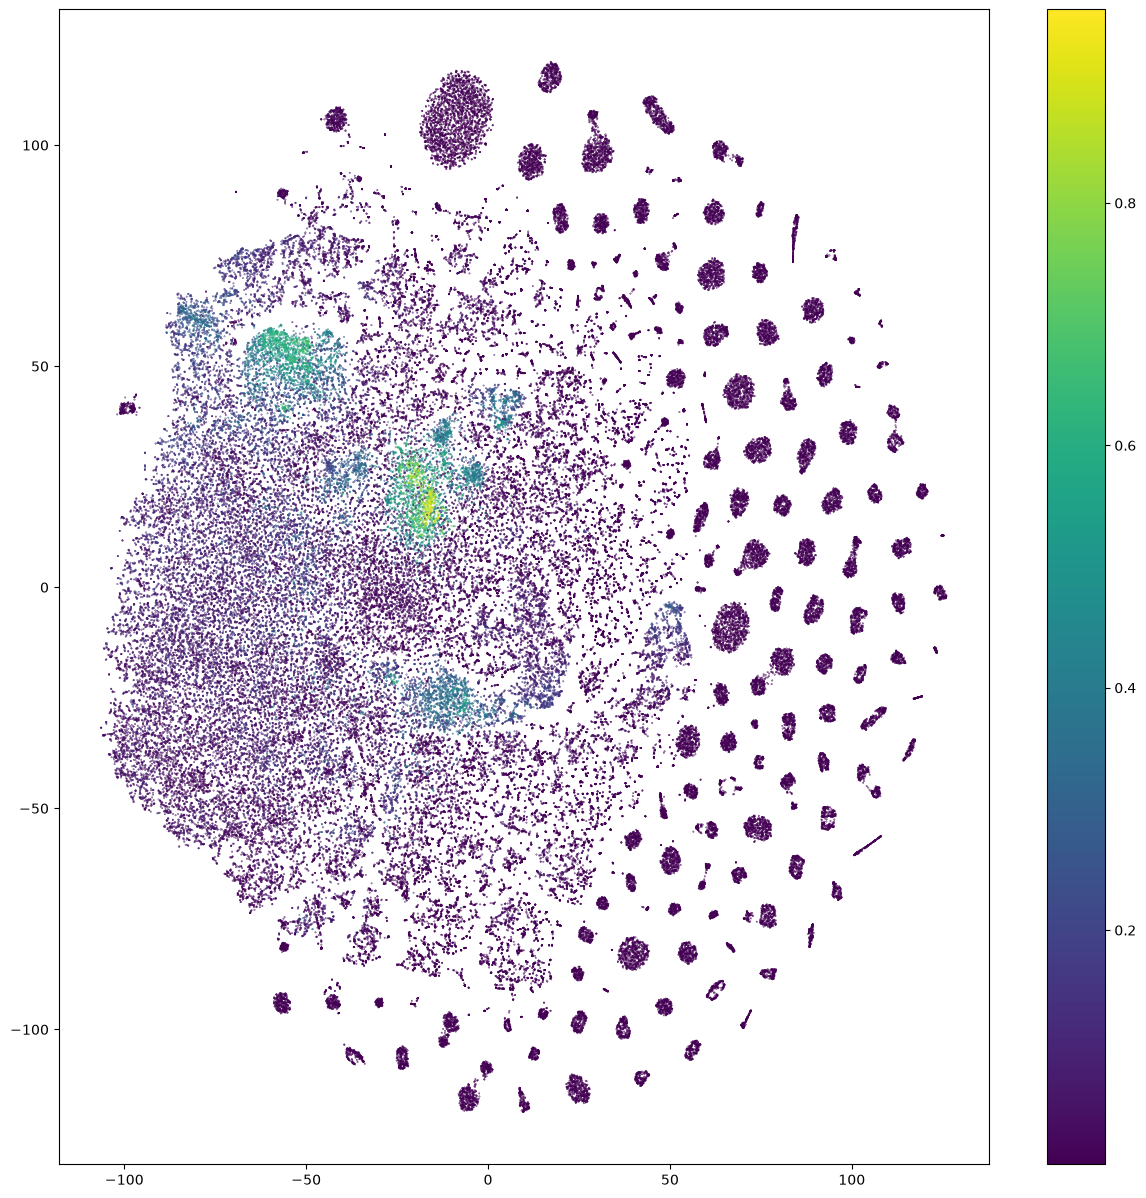

In [26]:
plt.figure(figsize=(15,15))

plt.scatter(E_pos_tsne[:, 0], E_pos_tsne[:, 1],c=open_rate, s=0.1)
plt.colorbar()
plt.show()

In [8]:
umap_pos = umap.UMAP(n_components=2, random_state=42)
umap_neg = umap.UMAP(n_components=2, random_state=42)

In [9]:
E_pos_umap = umap_pos.fit_transform(E_pos)

/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


In [10]:
E_neg_umap = umap_neg.fit_transform(E_neg)

/home/tim4ik/main_code_base/python_projects/Active-Learning-for-Email-Interaction-Dynamics/.venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


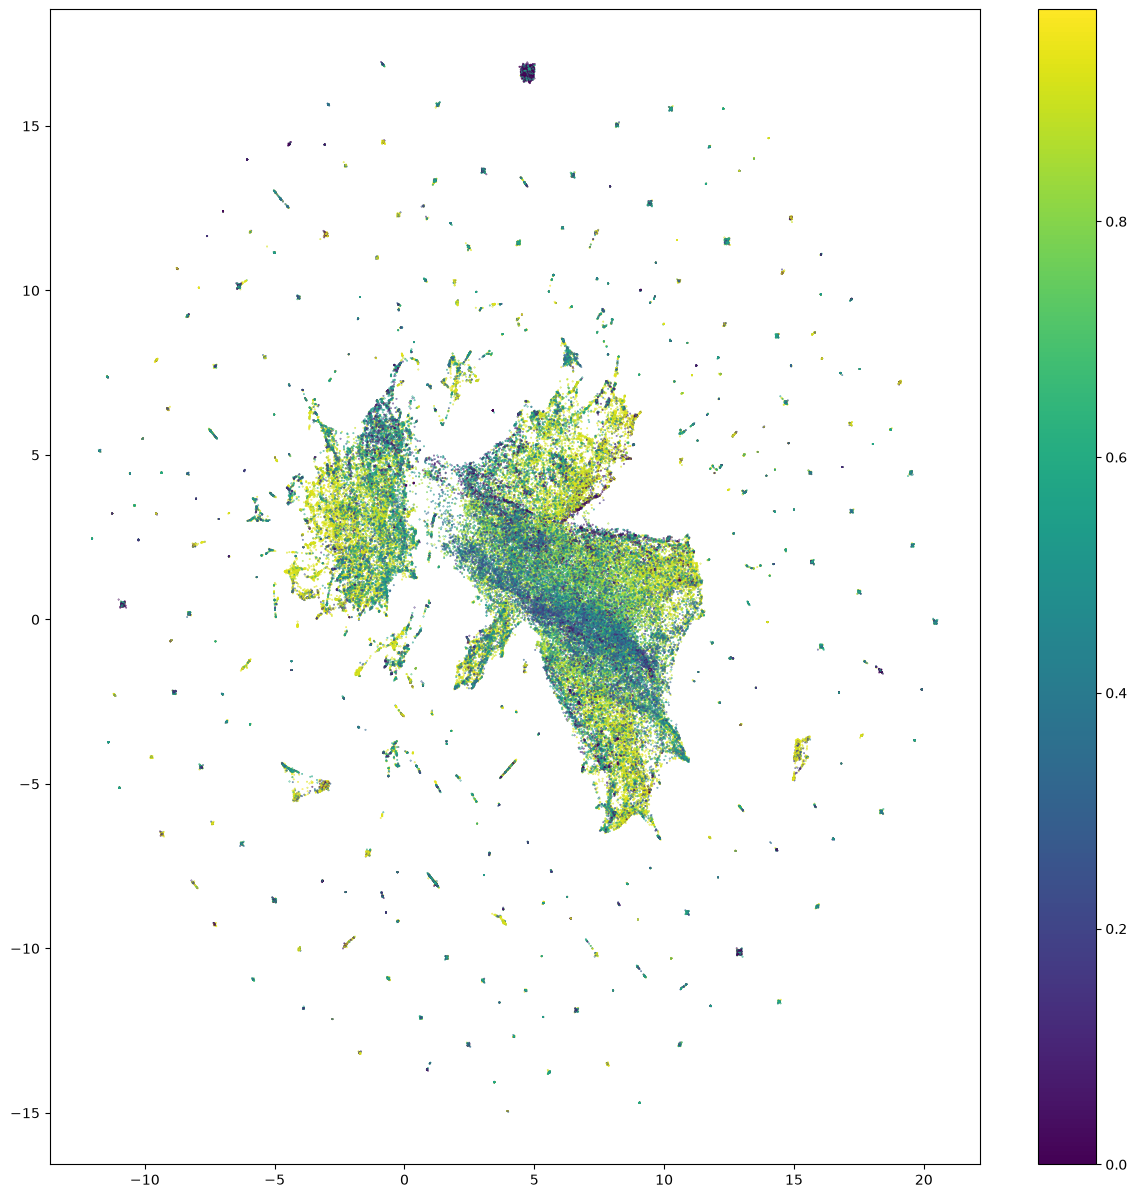

In [27]:
plt.figure(figsize=(15,15))

plt.scatter(E_neg_umap[:, 0], E_neg_umap[:, 1], c= non_open_rate,s=0.1)
plt.colorbar()
plt.show()

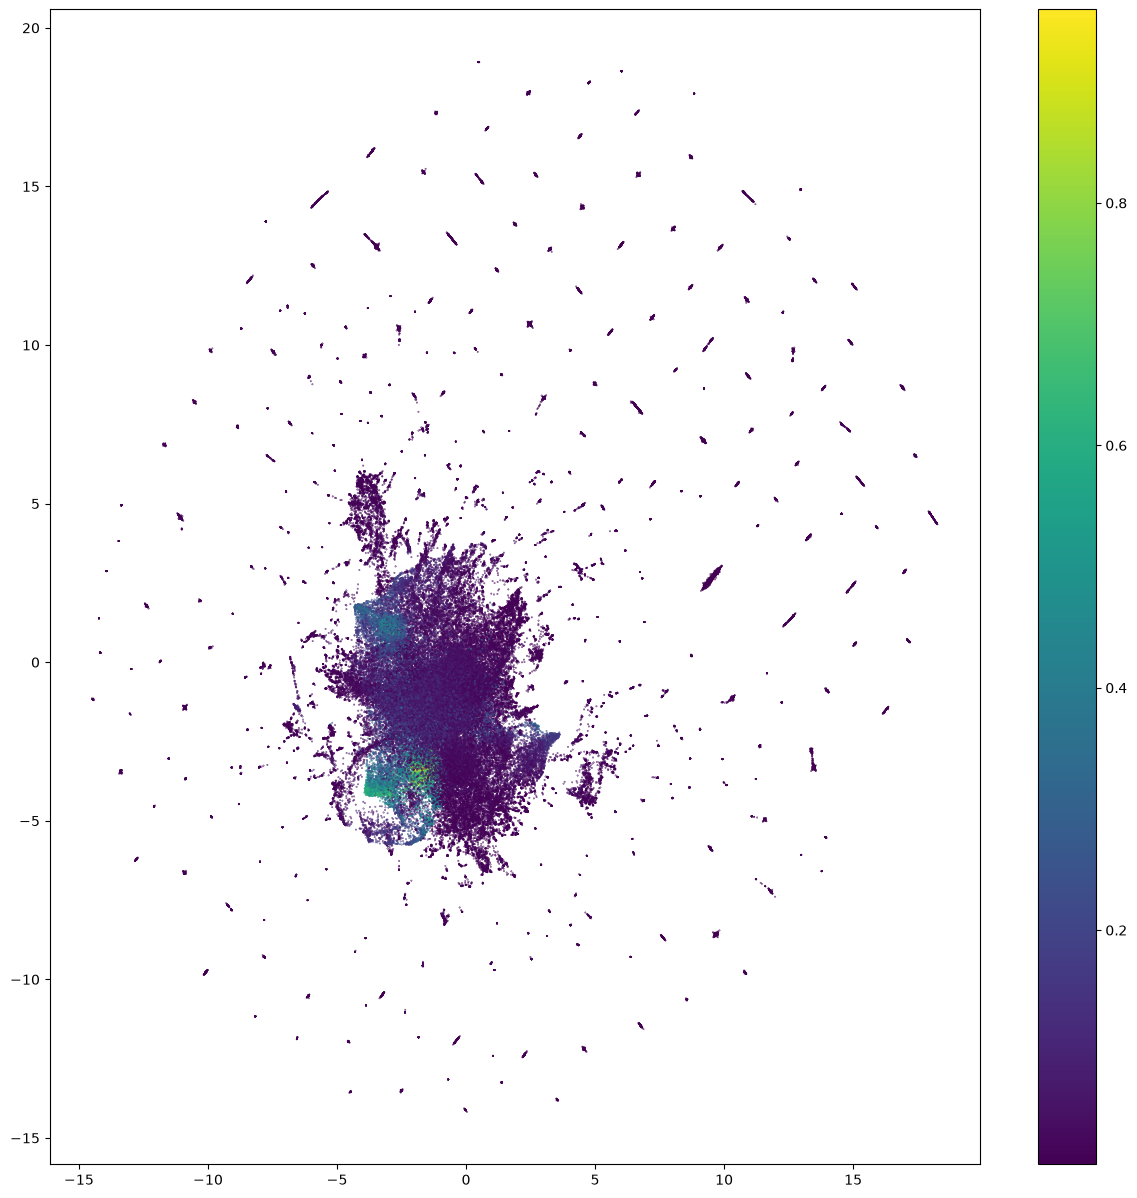

In [28]:
plt.figure(figsize=(15,15))

plt.scatter(E_pos_umap[:, 0], E_pos_umap[:, 1], c = open_rate,s=0.1)

plt.colorbar()
plt.show()

In [10]:
X_pos.shape, X_neg.shape

((149, 130802), (149, 130802))

In [11]:
pos_embeddings  = X_pos @ E_pos
neg_embeddings  = X_neg @ E_neg

In [12]:
tsne_em_pos = TSNE(n_components=2, random_state=42, n_jobs=2)
tsne_em_neg = TSNE(n_components=2, random_state=42, n_jobs=2)

In [13]:
em_pos_tsne = tsne_em_pos.fit_transform(pos_embeddings)
em_neg_tsne = tsne_em_neg.fit_transform(neg_embeddings)

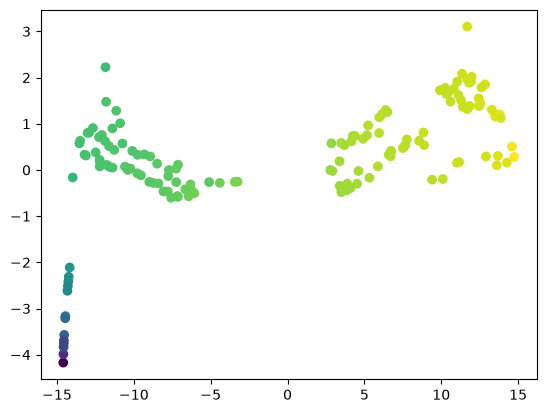

In [17]:
plt.scatter(em_neg_tsne[:, 0], em_neg_tsne[:, 1], c = np.mean(X_neg,axis=1))

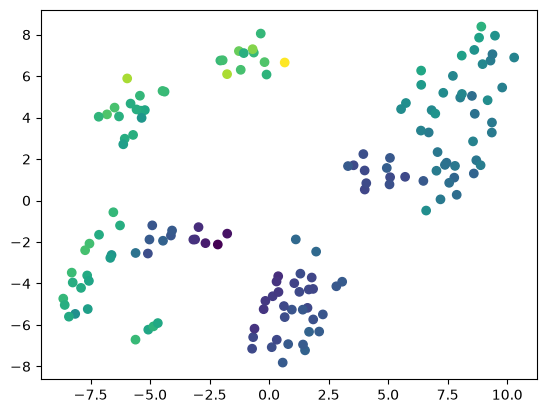

In [18]:
plt.scatter(em_pos_tsne[:, 0], em_pos_tsne[:, 1], c = np.mean(X_pos,axis=1))

In [ ]:
pos_embeddings

array([[-3.1406915e+02, -1.0316505e+02,  2.2814043e+02, ...,
        -2.5710699e+02, -8.2381630e+00, -2.3581659e+02],
       [-2.9858691e+02, -1.2825134e+02,  1.4979343e+02, ...,
        -2.0262727e+02, -6.8660927e+01, -1.0513924e+02],
       [-3.6089948e+02, -2.4691820e+02,  2.4726422e+02, ...,
        -5.2797437e+02, -2.1596440e+02, -1.2935370e+02],
       ...,
       [-3.3747494e+01, -1.4822475e+01, -1.5109302e+02, ...,
         5.8795692e+01,  1.2004185e-01,  6.3794186e+01],
       [-5.4281166e+01,  6.9241824e+00, -2.0520255e+02, ...,
         6.1249313e+01,  4.4114357e+01, -8.7236633e+00],
       [-5.5139526e+01, -2.0424921e+01, -2.0298915e+02, ...,
         2.6532188e+01, -7.1940174e+00,  8.4484360e+01]],
      shape=(149, 16), dtype=float32)